# Notebook 09 (OPTIONAL APPENDIX) - The real-world shortcut: pytesseract

*Time: about 30-45 minutes. This notebook is optional and the only one that uses a library outside the core list.*

## What you will learn
- Real OCR = **segmentation + a trained model**. We built the first half. Tesseract adds a model trained on millions of examples.
- How to call `pytesseract` safely (the notebook never crashes if it is missing).
- How its answers compare with our template matcher, on the same pictures.

## Prerequisites
- Notebooks 05, 06 and 08.
- *Optional* installation for the Tesseract part (the notebook runs without it):
  1. Install the **Tesseract program** (Windows installer from the UB-Mannheim build, `brew install tesseract` on macOS, `sudo apt install tesseract-ocr` on Linux).
  2. Then `pip install pytesseract`.

## Why it needs a trained model
Our template matcher stores **26 + 10 pictures**. Tesseract stores a **neural network** that has *learned* what characters look like in countless fonts, sizes and conditions. Learning from examples is exactly what you cannot do with simple pixel comparison.

### What this code does

We load the libraries. `matcher` is our own finished toolbox (`matcher.py` in the main folder): it contains the functions we built step by step in Notebooks 05, 06 and 08.

In [1]:
import sys                                    # lets us change where Python looks for files
sys.path.append("..")                         # also look one folder up (utils.py lives there)
import cv2                                    # OpenCV
import matcher                                # our template matcher (from Notebooks 05-08)
from utils import load, show                  # our helpers
print("Libraries loaded - ready to go!")      # a visible sign that everything worked

Libraries loaded - ready to go!


### What you should see / Why we care

`Libraries loaded - ready to go!`

### What this code does

`IMAGE_PATH` is the first test picture: the two numbers **427** and **1058**. We read it with **our** matcher: find boxes, recognise each digit, and split numbers at wide gaps.

template matcher says: ['427', '1058']


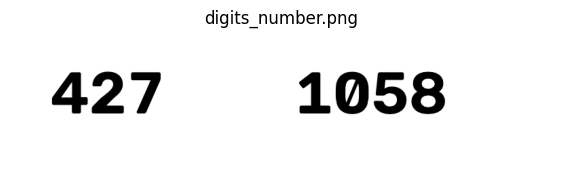

In [2]:
IMAGE_PATH = "../assets/digits_number.png"                 # <- change me
gray = cv2.cvtColor(load(IMAGE_PATH), cv2.COLOR_BGR2GRAY)  # gray picture
templates = matcher.make_templates(matcher.DIGITS)         # our ten digit templates
thresh, boxes = matcher.find_boxes(gray)                   # white digits on black + boxes
our_answer = matcher.read_row(thresh, boxes, templates)    # list of numbers as text
print("template matcher says:", our_answer)
show(gray, "digits_number.png", size=(7, 2))

### What you should see / Why we care

`template matcher says: ['427', '1058']`

### What this code does

Now **pytesseract**: five lines inside `try`. If the library is not installed (`ImportError`) or the Tesseract program is missing, we print a friendly message and carry on. `--psm 7` means "this picture is one line of text" and the whitelist restricts it to digits.

In [3]:
try:
    import pytesseract                                              # needs: pip install pytesseract
    config = "--psm 7 -c tessedit_char_whitelist=0123456789 "       # one line, digits only
    tesseract_answer = pytesseract.image_to_string(gray, config=config).strip()
    print("pytesseract says:", tesseract_answer)
except ImportError:
    print("pytesseract is not installed. Run:  pip install pytesseract  (and install Tesseract itself)")
except Exception as error:
    print("The Tesseract program was not found, skipping. Details:", error)

The Tesseract program was not found, skipping. Details: tesseract is not installed or it's not in your PATH. See README file for more information.


### What you should see / Why we care

With Tesseract installed: `pytesseract says: 427 1058` (the exact text can vary slightly between Tesseract versions). Without it you see an install message, and that is fine: the notebook continues.

## The fair fight: a font our templates have never seen

On neat pictures drawn with our own font, a template matcher can match a trained model. The difference appears when the font changes. `digits_real_font.png` was drawn with a normal computer font. It contains **2026, 88, 9, 305, 1999**.

### What this code does

Our matcher reads the picture row by row (the capstone function `read_all_numbers`).

template matcher says: [['2025', '88'], ['9', '305', '1999']]
the picture really says: [['2026', '88'], ['9', '305', '1999']]


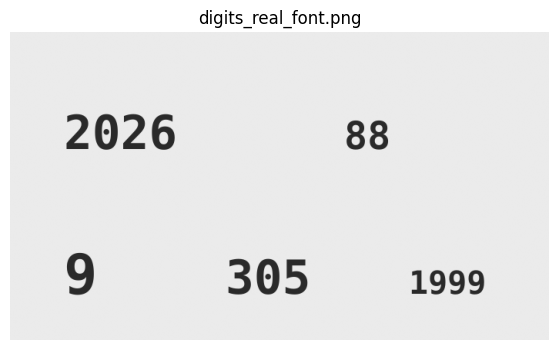

In [4]:
real_path = "../assets/digits_real_font.png"               # a real-world font
real_gray = cv2.cvtColor(load(real_path), cv2.COLOR_BGR2GRAY)
our_rows = matcher.read_all_numbers(real_gray)             # list of rows, each a list of numbers
print("template matcher says:", our_rows)
print("the picture really says: [['2026', '88'], ['9', '305', '1999']]")
show(real_gray, "digits_real_font.png", size=(7, 4))

### What you should see / Why we care

`template matcher says: [['2025', '88'], ['9', '305', '1999']]`. One digit is wrong: **2025** instead of **2026**.

### What this code does

The same picture through Tesseract (`--psm 11` = "find sparse text anywhere in the picture"). We split the answer into words with `.split()`.

In [5]:
try:
    import pytesseract                                              # needs: pip install pytesseract
    config = "--psm 11 -c tessedit_char_whitelist=0123456789 "      # sparse digits
    words = pytesseract.image_to_string(real_gray, config=config).split()
    print("pytesseract says:", words)
except ImportError:
    print("pytesseract is not installed. Run:  pip install pytesseract  (and install Tesseract itself)")
except Exception as error:
    print("The Tesseract program was not found, skipping. Details:", error)

The Tesseract program was not found, skipping. Details: tesseract is not installed or it's not in your PATH. See README file for more information.


### What you should see / Why we care

With Tesseract installed you should see all five numbers, in order: `['2026', '88', '9', '305', '1999']` (order and spacing may vary with the version). Because the trained model has seen many fonts, it is not fooled by a new one. Without Tesseract you see an install message.

## Take-away
| | Our template matcher | Tesseract |
|---|---|---|
| Needs | NumPy + OpenCV only | Tesseract program + pytesseract |
| Knows | 36 pictures we drew | millions of learned examples |
| Fonts | only ours | many |
| Tilt / noise | breaks quickly | much more robust |
| Best for | **understanding** how it works | **real jobs** |

Now you know what is inside the black box: **find the characters (segmentation), then decide which character each one is (recognition)**. Tesseract does the second part with a trained model; we did it with pictures and arithmetic.